# 01 - Exploratory analysis: who churns?

Dataset: IBM Telco Customer Churn sample (7,043 customers, 21 columns).
All cleaning and feature code lives in `src/churn` so this notebook and the
training pipeline run the exact same steps.

Questions for this pass:
1. What is the overall churn rate?
2. Which customer segments churn most?
3. How do tenure and monthly charges relate to churn?

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn.features import churn_rate_by, load_data

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

df = load_data("../data/raw/telco_churn.csv")
print(f"Rows: {len(df)}, columns: {df.shape[1]}")
df.head()

Rows: 7043, columns: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.850,29.850,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.950,1889.500,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.850,108.150,1
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.300,1840.750,0
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.700,151.650,1


In [2]:
overall = df["Churn"].mean()
print(f"Overall churn rate: {overall:.1%} ({int(df['Churn'].sum())} of {len(df)} customers)")
print(f"Missing TotalCharges values (tenure 0 customers): {df['TotalCharges'].isna().sum()}")

Overall churn rate: 26.5% (1869 of 7043 customers)
Missing TotalCharges values (tenure 0 customers): 11


## Churn by contract type

Contract is the single clearest split in the data. Month-to-month customers
churn at roughly 15 times the rate of two year customers.

                churn_rate  customers
Contract                             
Month-to-month       0.427       3875
One year             0.113       1473
Two year             0.028       1695


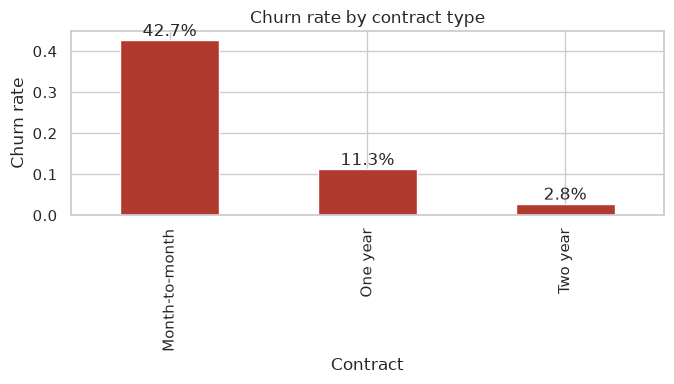

In [3]:
contract = churn_rate_by(df, "Contract")
print(contract)

fig, ax = plt.subplots(figsize=(7, 4))
contract["churn_rate"].plot(kind="bar", ax=ax, color="#b03a2e")
ax.set_ylabel("Churn rate")
ax.set_xlabel("Contract")
ax.set_title("Churn rate by contract type")
for i, v in enumerate(contract["churn_rate"]):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
fig.tight_layout()
fig.savefig("../reports/figures/churn_by_contract.png", dpi=150)
plt.show()

## Churn by tenure

Churn is front loaded. Nearly half of first year customers leave, and the
rate falls steadily the longer a customer stays.

             churn_rate  customers
tenure_band                       
0-12              0.474       2186
13-24             0.287       1024
25-48             0.204       1594
49-72             0.095       2239
Median tenure, churned: 10.0 months


Median tenure, stayed:  38.0 months


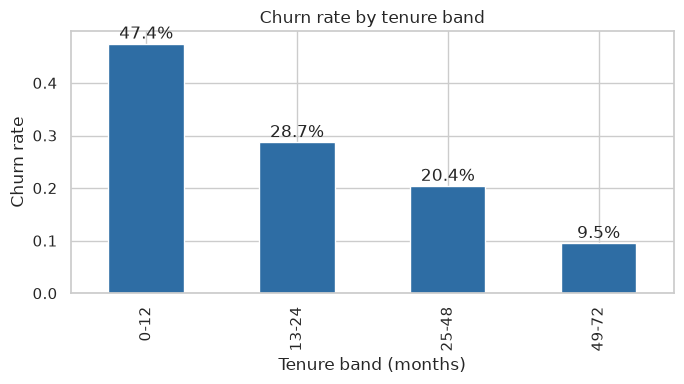

In [4]:
df["tenure_band"] = pd.cut(
    df["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0-12", "13-24", "25-48", "49-72"],
).astype(str)
bands = churn_rate_by(df, "tenure_band")
print(bands)
print(f"Median tenure, churned: {df[df['Churn'] == 1]['tenure'].median()} months")
print(f"Median tenure, stayed:  {df[df['Churn'] == 0]['tenure'].median()} months")

fig, ax = plt.subplots(figsize=(7, 4))
bands["churn_rate"].plot(kind="bar", ax=ax, color="#2e6da4")
ax.set_ylabel("Churn rate")
ax.set_xlabel("Tenure band (months)")
ax.set_title("Churn rate by tenure band")
for i, v in enumerate(bands["churn_rate"]):
    ax.text(i, v + 0.01, f"{v:.1%}", ha="center")
fig.tight_layout()
fig.savefig("../reports/figures/churn_by_tenure_band.png", dpi=150)
plt.show()

## Churn by internet service and support add-ons

Fiber optic customers churn at more than twice the DSL rate. Customers
without tech support or online security churn at about 42 percent, close
to three times the rate of customers who have them.

InternetService
                 churn_rate  customers
InternetService                       
Fiber optic           0.419       3096
DSL                   0.190       2421
No                    0.074       1526

TechSupport
                     churn_rate  customers
TechSupport                               
No                        0.416       3473
Yes                       0.152       2044
No internet service       0.074       1526

OnlineSecurity
                     churn_rate  customers
OnlineSecurity                            
No                        0.418       3498
Yes                       0.146       2019
No internet service       0.074       1526



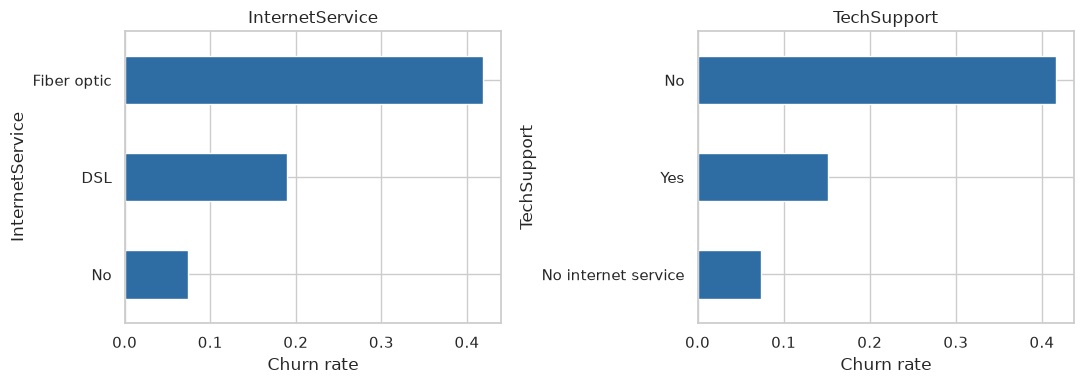

In [5]:
for col in ["InternetService", "TechSupport", "OnlineSecurity"]:
    print(col)
    print(churn_rate_by(df, col))
    print()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col in zip(axes, ["InternetService", "TechSupport"]):
    rates = churn_rate_by(df, col)["churn_rate"].sort_values()
    rates.plot(kind="barh", ax=ax, color="#2e6da4")
    ax.set_xlabel("Churn rate")
    ax.set_title(col)
fig.tight_layout()
fig.savefig("../reports/figures/churn_by_internet_and_support.png", dpi=150)
plt.show()

## Payment method and the worst combined segment

Electronic check payers churn at 45 percent. The single worst large
segment is fiber optic on a month-to-month contract.

                           churn_rate  customers
PaymentMethod                                   
Electronic check                0.453       2365
Mailed check                    0.191       1612
Bank transfer (automatic)       0.167       1544
Credit card (automatic)         0.152       1522
Fiber optic + month-to-month: 2128 customers, churn rate 54.6%


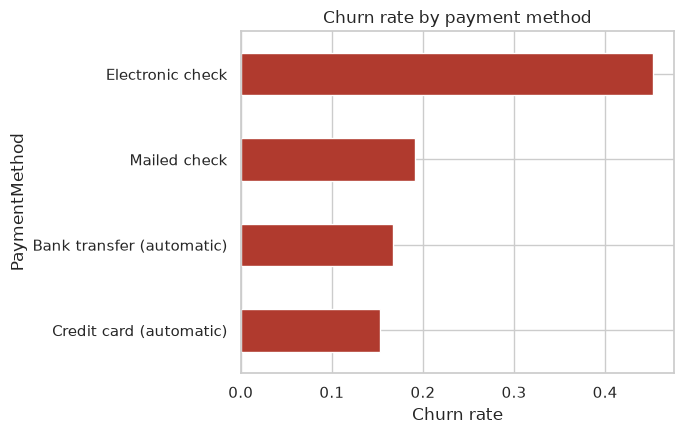

In [6]:
print(churn_rate_by(df, "PaymentMethod"))

combo = df[(df["InternetService"] == "Fiber optic") & (df["Contract"] == "Month-to-month")]
print(f"Fiber optic + month-to-month: {len(combo)} customers, churn rate {combo['Churn'].mean():.1%}")

fig, ax = plt.subplots(figsize=(7, 4.5))
rates = churn_rate_by(df, "PaymentMethod")["churn_rate"].sort_values()
rates.plot(kind="barh", ax=ax, color="#b03a2e")
ax.set_xlabel("Churn rate")
ax.set_title("Churn rate by payment method")
fig.tight_layout()
fig.savefig("../reports/figures/churn_by_payment_method.png", dpi=150)
plt.show()

## Monthly charges

Churners pay more per month on average (mean $74.44 versus $61.27), which
fits the fiber pattern: the expensive tier is also the least sticky.

Mean MonthlyCharges, churned: 74.44
Mean MonthlyCharges, stayed:  61.27


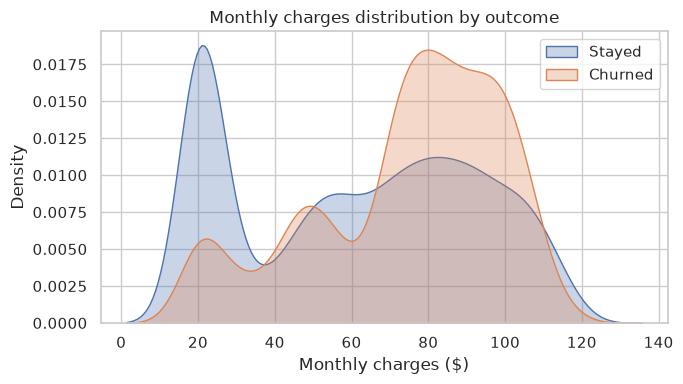

In [7]:
print("Mean MonthlyCharges, churned:", round(df[df["Churn"] == 1]["MonthlyCharges"].mean(), 2))
print("Mean MonthlyCharges, stayed: ", round(df[df["Churn"] == 0]["MonthlyCharges"].mean(), 2))

fig, ax = plt.subplots(figsize=(7, 4))
for label, sub in [("Stayed", df[df["Churn"] == 0]), ("Churned", df[df["Churn"] == 1])]:
    sns.kdeplot(sub["MonthlyCharges"], ax=ax, label=label, fill=True, alpha=0.3)
ax.set_xlabel("Monthly charges ($)")
ax.set_title("Monthly charges distribution by outcome")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/monthly_charges_distribution.png", dpi=150)
plt.show()

## Takeaways from EDA

- Overall churn is 26.5 percent.
- Contract type, tenure, internet service tier, support add-ons, and
  payment method carry the signal. Gender and phone service carry almost
  none (26.9 versus 26.2 percent, 26.7 versus 24.9 percent).
- The modeling notebook tests how far these segments go as a predictive
  model.